# Flight Delay Prediction: American Airlines

I denne notebook bygger vi en model, der forudsiger forsinkelser for **American Airlines (AA)** på indenrigsflyvninger i USA.

Datakilden er **Bureau of Transportation Statistics (BTS)** – datasættet *Reporting Carrier On-Time Performance* for januar–december 2025, med én række pr. flyvning.

## 1. Introduction

### Business question
> *"Can American Airlines' operations team use ML to predict flight delays (>15 min) before departure for proactive resource allocation?"*

Forsinkelser er dyre. FAA-finansierede *Total Delay Impact Study* (Ball et al., 2010) anslog de samlede omkostninger for den amerikanske økonomi til **ca. 33 mia. dollars om året**, fordelt på flyselskaber (besætning, brændstof, vedligehold), passagerer (tabt tid) og afledte tab. Hvis operations-teamet kender risikoen for en forsinkelse i god tid, kan de handle proaktivt: sætte reservefly og -besætning klar, omfordele gate-personale eller ombooke passagerer med korte forbindelser, før problemet opstår.

### ML question
Vi oversætter spørgsmålet til et **binært klassifikationsproblem**:

- **Enhed:** én planlagt AA-flyvning
- **Target:** `Delayed = 1`, hvis flyet ankommer **mere end 15 minutter** efter planen (DOT's officielle definition), ellers `0`
- **Prediction window: T-2 timer.** Forudsigelsen laves **2 timer før planlagt afgang**. Vi må derfor kun bruge information, der er kendt på det tidspunkt: køreplanen (dato, tid, rute, distance), det tildelte fly (`Tail_Number`) og historiske mønstre. Alt, der først kendes ved eller efter afgang, er udelukket.

### Hvorfor American Airlines?
Valget er data-drevet (se `airline_selection_analysis.ipynb`). Blandt de fem selskaber med over 300.000 flyvninger i 2025 har AA:
- den **højeste delay rate (ca. 25 %)**, så der er flest forsinkede eksempler at lære af
- et klart **hub-and-spoke-netværk** (ca. 47 % af afgangene fra DFW, CLT, MIA, ORD og PHX), som giver en operationel historie om, hvordan forsinkelser spreder sig fra knudepunkterne
- ca. 950.000 flyvninger, 1.194 ruter og 133 lufthavne, dvs. rigeligt data og variation

### Brug af AI
Generativ AI (Claude, Anthropic) er brugt som kodeassistent og sparringspartner i overensstemmelse med CBS' retningslinjer for brug af generativ AI. Al kode er gennemgået og kørt af gruppen, og analyser, fortolkninger og konklusioner er gruppens egne.

### Imports
Alle biblioteker importeres samlet her.

In [1]:
import time
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from fairlearn.metrics import (
    MetricFrame,
    false_positive_rate,
    selection_rate,
    true_positive_rate,
)
from fairlearn.postprocessing import ThresholdOptimizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

# Konsistent farvepalet til alle plots
COLOR_DELAYED = "#eb6834"  # orange: forsinket
COLOR_ONTIME = "#2a78d6"   # blå: til tiden
COLOR_REF = "#8a8984"      # grå: referencelinje

sns.set_theme(style="whitegrid", rc={
    "axes.edgecolor": "#d6d5d0",
    "grid.color": "#ecebe7",
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.labelsize": 11,
})

RANDOM_STATE = 42

## 2. Data Loading & Cleaning

### 2.1 Hent rå-data (januar–december 2025)

BTS udgiver hver måned som en zip-fil på:

```
https://transtats.bts.gov/PREZIP/On_Time_Reporting_Carrier_On_Time_Performance_1987_present_{year}_{month}.zip
```

Cellen nedenfor downloader hver måned til `data/` (springes over, hvis zip-filen allerede findes), læser CSV-filen direkte fra zip'en og samler alle 12 måneder til ét DataFrame.

Rå-filerne har over 100 kolonner. For at spare hukommelse indlæser vi kun dem, vi skal bruge:

| Kolonne | Formål |
|---|---|
| `FlightDate`, `Month`, `DayOfWeek`, `CRSDepTime` | Tidspunkt (planlagt, kendt på forhånd) |
| `Origin`, `Dest`, `Distance` | Rute (kendt på forhånd) |
| `Tail_Number` | Det tildelte fly (kendt ved T-2 timer) |
| `Reporting_Airline` | Til at filtrere til AA |
| `Cancelled`, `Diverted` | Til at fjerne flyvninger uden ankomst |
| `ArrDelay` | Til at lave target |
| `CarrierDelay`, `WeatherDelay`, `NASDelay`, `LateAircraftDelay`, `SecurityDelay` | Forsinkelsesårsager, **kun til EDA** |

In [2]:
YEAR = 2025
MONTHS = range(1, 13)
URL_TEMPLATE = (
    "https://transtats.bts.gov/PREZIP/"
    "On_Time_Reporting_Carrier_On_Time_Performance_1987_present_{year}_{month}.zip"
)

DELAY_CAUSES = ["CarrierDelay", "WeatherDelay", "NASDelay", "LateAircraftDelay", "SecurityDelay"]
COLUMNS = [
    "FlightDate", "Month", "DayOfWeek", "Origin", "Dest", "CRSDepTime",
    "ArrDelay", "Cancelled", "Diverted", "Distance", "Tail_Number",
    *DELAY_CAUSES, "Reporting_Airline",
]

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

monthly_frames = []

for month in MONTHS:
    url = URL_TEMPLATE.format(year=YEAR, month=month)
    zip_path = DATA_DIR / f"ontime_{YEAR}_{month:02d}.zip"

    # 1) Download (kun hvis vi ikke allerede har filen)
    if not zip_path.exists():
        print(f"Downloader {url} ...")
        with requests.get(url, stream=True, timeout=120) as r:
            r.raise_for_status()
            with open(zip_path, "wb") as f:
                for chunk in r.iter_content(chunk_size=1 << 20):
                    f.write(chunk)

    # 2) Læs CSV-filen direkte fra zip'en (kun de kolonner vi skal bruge)
    with zipfile.ZipFile(zip_path) as zf:
        csv_name = next(n for n in zf.namelist() if n.lower().endswith(".csv"))
        with zf.open(csv_name) as f:
            df_month = pd.read_csv(f, usecols=COLUMNS, low_memory=False)

    print(f"{YEAR}-{month:02d}: {len(df_month):,} rækker")
    monthly_frames.append(df_month)

# 3) Saml alle måneder til ét DataFrame
raw = pd.concat(monthly_frames, ignore_index=True)
print(f"\nSamlet: {len(raw):,} flyvninger (alle selskaber), {raw.shape[1]} kolonner")

2025-01: 539,747 rækker


2025-02: 504,884 rækker


2025-03: 600,872 rækker


2025-04: 583,950 rækker


2025-05: 605,648 rækker


...

2025-09: 562,439 rækker


2025-10: 605,844 rækker


2025-11: 570,550 rækker


2025-12: 582,304 rækker



Samlet: 7,001,619 flyvninger (alle selskaber), 17 kolonner


### 2.2 Filtrér til American Airlines

Vi beholder kun AA's flyvninger. Derefter er `Reporting_Airline` konstant og kan droppes.

In [3]:
df = raw[raw["Reporting_Airline"] == "AA"].drop(columns=["Reporting_Airline"])

print(f"AA-flyvninger: {len(df):,} af {len(raw):,} ({len(df) / len(raw):.1%})")

AA-flyvninger: 973,653 af 7,001,619 (13.9%)


### 2.3 Fjern aflyste og omdirigerede flyvninger

Aflyste (`Cancelled == 1`) og omdirigerede (`Diverted == 1`) flyvninger ankommer aldrig normalt til destinationen og har derfor ingen meningsfuld ankomstforsinkelse. Vi fjerner dem, og derefter indeholder de to kolonner kun 0 og kan droppes.

In [4]:
n_before = len(df)

df = df[(df["Cancelled"] != 1) & (df["Diverted"] != 1)]
df = df.drop(columns=["Cancelled", "Diverted"])

print(f"Fjernet {n_before - len(df):,} aflyste/omdirigerede flyvninger")
print(f"Tilbage: {len(df):,} rækker")

Fjernet 20,812 aflyste/omdirigerede flyvninger
Tilbage: 952,841 rækker


### 2.4 Fjern rækker uden ankomstforsinkelse

Target bygges på `ArrDelay`, så rækker, hvor den mangler, kan ikke bruges.

In [5]:
n_before = len(df)

df = df.dropna(subset=["ArrDelay"]).reset_index(drop=True)

print(f"Fjernet {n_before - len(df):,} rækker med manglende ArrDelay")
print(f"Tilbage: {len(df):,} rækker")

Fjernet 0 rækker med manglende ArrDelay
Tilbage: 952,841 rækker


### 2.5 Target-variabel: `Delayed`

Vi følger DOT's officielle definition: en flyvning er **forsinket**, hvis den ankommer **mere end 15 minutter** efter planen.

- `Delayed = 1`: forsinket (`ArrDelay > 15`)
- `Delayed = 0`: til tiden

In [6]:
df["Delayed"] = (df["ArrDelay"] > 15).astype(int)

### 2.6 Target leakage: ArrDelay og forsinkelsesårsager

**Target leakage** opstår, når en model trænes på information, som ikke ville være tilgængelig på forudsigelsestidspunktet. Modellen ser fremragende ud under evaluering, men virker ikke i praksis. Kapoor & Narayanan (2023, *"Leakage and the reproducibility crisis in machine-learning-based science"*, Patterns) viser, at leakage er en af de hyppigste årsager til overoptimistiske resultater i ML-baseret forskning. Deres taksonomi omfatter netop features, der ikke er *legitime* på forudsigelsestidspunktet.

To grupper af kolonner er leakage i vores T-2-timers-setup:

| Kolonne(r) | Hvorfor de er leakage |
|---|---|
| `ArrDelay` | Er selve svaret: `Delayed` er beregnet direkte ud fra den. Kendes først ved ankomst |
| `CarrierDelay`, `WeatherDelay`, `NASDelay`, `LateAircraftDelay`, `SecurityDelay` | Registreres af selskabet **efter** flyvningen, og BTS udfylder dem **kun for flyvninger, der er forsinket ≥ 15 min**. En værdi forskellig fra NaN afslører derfor næsten direkte target |

Årsagerne er dog meget nyttige til at **forstå** forsinkelser (fx hvor stor en del, der skyldes kaskader fra tidligere ture). Vi gemmer dem derfor i et separat DataFrame, `delay_causes`, til EDA og fjerner dem fra hoveddatasættet, så de ikke ved en fejl ender som features.

In [7]:
# Separat DataFrame til EDA: samme indeks som df, så de kan joines igen
delay_causes = df[["ArrDelay", *DELAY_CAUSES]].copy()

# Fjern leakage-kolonnerne fra hoveddatasættet
df = df.drop(columns=["ArrDelay", *DELAY_CAUSES])

print("delay_causes:", delay_causes.shape)
print("df:          ", df.shape)
print("Kolonner i df:", list(df.columns))

delay_causes: (952841, 6)
df:           (952841, 9)
Kolonner i df: ['Month', 'DayOfWeek', 'FlightDate', 'Tail_Number', 'Origin', 'Dest', 'CRSDepTime', 'Distance', 'Delayed']


### 2.7 Datasættets styrker og begrænsninger

**Styrker**
- **Fuld population, ikke et sample:** BTS indeholder *alle* AA's indenrigsflyvninger i 2025 (lovpligtig indrapportering), så der er ingen stikprøveskævhed.
- **Officiel og standardiseret kilde:** Samme definitioner på tværs af måneder og lufthavne, og den officielle 15-minutters definition af forsinkelse.
- **Et helt år:** Dækker alle sæsoner (vintervejr, sommertrafik, ferier), så modellen kan lære sæsonmønstre.
- **Stort datasæt:** Ca. 950.000 flyvninger giver rigeligt data til træning, validering og test.
- **Tail_Number:** Gør det muligt at følge det enkelte fly gennem dagen og modellere kaskadeforsinkelser.

**Begrænsninger**
- **Intet vejr:** Vejr er en væsentlig årsag til forsinkelser, men indgår ikke i BTS-dataene. Modellen kan kun fange vejr indirekte (fx via måned og lufthavn).
- **Kun ét år:** Mønstre fra 2025 (fx en bestemt hub med problemer eller ændringer i køreplanen) gælder ikke nødvendigvis i 2026. Vi kan ikke teste, om modellen holder over tid.
- **Selektion ved fjernelse af aflyste fly:** Aflysninger sker ofte på de dårligste dage. Når vi fjerner dem, undervurderer vi de mest forstyrrede driftsdage.
- **Kun indenrigsflyvninger:** AA's internationale netværk er ikke med.
- **Ingen operationelle data:** Passagertal, bemanding, vedligehold og gate-belægning kendes ikke, selvom de sandsynligvis påvirker forsinkelser.
- **Observationsdata:** Vi kan finde sammenhænge, men ikke årsager. Fx er afgangstidspunktet valgt af AA og ikke tilfældigt tildelt.

### 2.8 Class balance

Vi tjekker fordelingen mellem forsinkede og rettidige flyvninger. Hvis klasserne er skævt fordelt, er accuracy et misvisende mål: en model, der *altid* gætter "til tiden", får høj accuracy uden at være nyttig. Det skal vi tage højde for i modelleringen (class weights og metrics som ROC-AUC/PR-AUC).

                Antal  Andel
Til tiden (0)  714611  75.0%
Forsinket (1)  238230  25.0%


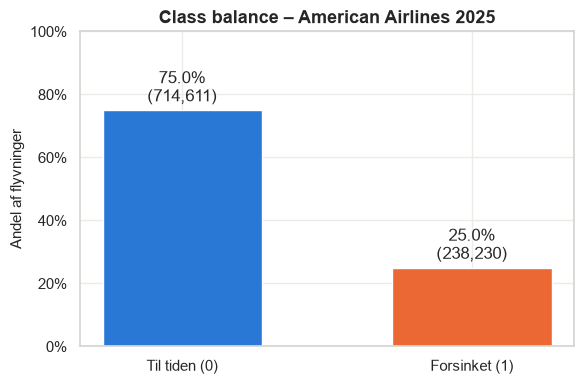

In [8]:
counts = df["Delayed"].value_counts().sort_index()
shares = counts / counts.sum()

balance = pd.DataFrame({"Antal": counts, "Andel": shares.map("{:.1%}".format)})
balance.index = ["Til tiden (0)", "Forsinket (1)"]
print(balance)

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(balance.index, shares.values, color=[COLOR_ONTIME, COLOR_DELAYED], width=0.55)
ax.bar_label(bars, labels=[f"{s:.1%}\n({c:,})" for s, c in zip(shares, counts)], padding=3)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_ylim(0, 1)
ax.set_ylabel("Andel af flyvninger")
ax.set_title("Class balance – American Airlines 2025")
plt.tight_layout()
plt.show()

### 2.9 Gem det rensede datasæt

Vi gemmer hoveddatasættet som `cleaned_flights_aa.csv`, så de næste sektioner kan starte herfra uden at downloade og rense igen.

In [9]:
df.to_csv("cleaned_flights_aa.csv", index=False)

print(f"Gemt cleaned_flights_aa.csv ({len(df):,} rækker, {df.shape[1]} kolonner)")
display(df.head())

Gemt cleaned_flights_aa.csv (952,841 rækker, 9 kolonner)


,Month,DayOfWeek,FlightDate,Tail_Number,Origin,Dest,CRSDepTime,Distance,Delayed
0,1,3,2025-01-01,N104NN,JFK,LAX,659,2475.0,0
1,1,4,2025-01-02,N110AN,JFK,LAX,659,2475.0,0
2,1,5,2025-01-03,N106NN,JFK,LAX,659,2475.0,0
3,1,6,2025-01-04,N117AN,JFK,LAX,700,2475.0,0
4,1,7,2025-01-05,N104NN,JFK,LAX,659,2475.0,0
